# Indian E-Commerce Sales & Returns Analysis

**Author:** Vivek Saini — Data Analyst (Python · pandas · SQL · matplotlib)

## The problem

Imagine a mid-size online seller in India. Orders are coming in every day,
sales look good — but at the end of the month, the profit is much smaller
than expected. The owner has some guesses about why: too many returns,
too many cash-on-delivery (COD) orders, discounts that are too deep, and
slow delivery in some cities. But guesses are not proof.

So I took one full year of the seller's orders (Jan–Dec 2025) and checked
each guess with data. This notebook is the full story: the messy raw file,
how I cleaned it, the questions I asked, and what the numbers actually say.

## Questions I wanted to answer

1. How big is the returns problem, and which products come back the most?
2. Do COD orders really come back more than prepaid orders?
3. Do big discounts make money, or do they just look good?
4. Does slow delivery push people to return things?
5. Which cities and which product + payment mixes earn the least?

**One honest note:** this dataset is made by me with Python
(`generate_data.py`, seed 42). It is not a real company's data. But I built
it to behave like real Indian e-commerce — fashion returns for size issues,
COD behaviour, festival-season spikes in October–November, and slow
delivery in a few cities — so the full workflow (cleaning, analysis, SQL,
charts) is the same work I would do on a real export.

## 1 · First look at the raw data

The raw file is a direct export, and it looks like one. Let me load it and
see what we have.

In [1]:
%matplotlib inline
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.axisbelow": True})
BLUE, RED, GREEN, ORANGE = "#2563eb", "#dc2626", "#16a34a", "#ea580c"

raw = pd.read_csv("data/ecommerce_orders_raw.csv")
print("Shape:", raw.shape)
raw.head(3)

Shape: (10045, 16)


,order_id,order_date,customer_id,city,state,category,product,quantity,unit_price,discount_pct,payment_mode,delivery_days,order_status,return_reason,shipping_fee,order_value
0,ORD-04006,2025-11-16,CUST-02572,Patna,Bihar,Home & Kitchen,Storage Boxes (Set of 4),2,579.0,30.7,COD,NaN,Cancelled,NaN,0.0,802.0
1,ORD-01161,08/08/2025,CUST-02186,Bengaluru,Karnataka,Sports,Cricket Bat,1,2919.0,0.0,UPI,4.0,Delivered,NaN,0.0,2919.0
2,ORD-02327,2025/06/16,CUST-03994,delhi,Delhi,Beauty,Matte Lipstick,1,449.0,6.3,Card,2.0,Delivered,NaN,49.0,421.0


## 2 · The data is messy — let me show you

Before any analysis, I checked four things I always check first: duplicate
rows, missing values, dates, and names written in different ways.

In [2]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("\nMissing values:")
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())
print("\nThe same city, written many ways:")
print(raw["city"].value_counts().head(20).to_string())
print("\nDates also come in different formats:")
print(raw["order_date"].head(8).tolist())

Exact duplicate rows: 45

Missing values:
state              70
unit_price         81
discount_pct      151
delivery_days     715
return_reason    8724
shipping_fee      100
order_value       100

The same city, written many ways:
city
Mumbai       1050
Bengaluru     992
Delhi         915
Hyderabad     769
Chennai       729
Ahmedabad     646
Pune          642
Surat         578
Kolkata       574
Jaipur        556
Lucknow       508
Patna         459
Kochi         453
Indore        453
delhi         156
New Delhi     112
Bangalore      81
bengaluru      64
DELHI          54
mumbai         54

Dates also come in different formats:
['2025-11-16', '08/08/2025', '2025/06/16', '21-09-2025', '05-08-2025', '03-07-2025', '2025-11-06', '16-08-2025']


## 3 · Cleaning the data

My cleaning steps, in order:

- Drop the exact duplicate rows (double entries from the export).
- Fix city names: trim spaces, and map spellings like `delhi `, `New Delhi`
  and `DELHI` to `Delhi`, and `Bangalore` to `Bengaluru`.
- Fill missing states from the city (I know which state each city is in).
- Turn all the date formats into real dates.
- Drop the few rows that have no price at all — there is no honest way to
  fix those.
- Fill a missing discount with the usual discount for that category.
- Rebuild a missing order value from price × quantity × (1 − discount).
- Fill a missing shipping fee with the seller's own rule: free above ₹499,
  otherwise ₹49.
- Fill missing delivery days with the usual days for that city.
- For returned orders with no reason written, mark the reason as
  "Not recorded" instead of guessing one.

In [3]:
CITY_FIX = {
    "delhi": "Delhi", "new delhi": "Delhi",
    "bangalore": "Bengaluru", "bengaluru": "Bengaluru",
    "mumbai": "Mumbai", "hyderabad": "Hyderabad", "chennai": "Chennai",
    "pune": "Pune", "kolkata": "Kolkata", "ahmedabad": "Ahmedabad",
    "jaipur": "Jaipur", "lucknow": "Lucknow", "indore": "Indore",
    "patna": "Patna", "kochi": "Kochi", "surat": "Surat",
}
CITY_STATE = {
    "Delhi": "Delhi", "Mumbai": "Maharashtra", "Bengaluru": "Karnataka",
    "Hyderabad": "Telangana", "Chennai": "Tamil Nadu", "Pune": "Maharashtra",
    "Kolkata": "West Bengal", "Ahmedabad": "Gujarat", "Jaipur": "Rajasthan",
    "Lucknow": "Uttar Pradesh", "Indore": "Madhya Pradesh", "Patna": "Bihar",
    "Kochi": "Kerala", "Surat": "Gujarat",
}

df = raw.drop_duplicates().copy()
print("Rows before:", len(raw), "| after dropping duplicates:", len(df))

df["city"] = (df["city"].astype(str).str.strip().str.lower()
              .map(CITY_FIX).fillna(df["city"].str.strip()))
df["state"] = df["state"].fillna(df["city"].map(CITY_STATE))
df["order_date"] = pd.to_datetime(df["order_date"], format="mixed",
                                  dayfirst=True, errors="coerce")
df = df.dropna(subset=["order_date"])

for c in ["quantity", "unit_price", "discount_pct", "delivery_days",
          "shipping_fee", "order_value"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["unit_price", "quantity"])
df["discount_pct"] = df.groupby("category")["discount_pct"].transform(
    lambda s: s.fillna(s.median()))
rebuilt = (df["quantity"] * df["unit_price"]
           * (1 - df["discount_pct"] / 100)).round()
df["order_value"] = df["order_value"].fillna(rebuilt)
df["shipping_fee"] = df["shipping_fee"].fillna(
    pd.Series(np.where(df["order_value"] >= 499, 0, 49), index=df.index))
shipped_mask = df["order_status"] != "Cancelled"
med_days = df[shipped_mask].groupby("city")["delivery_days"].median()
df.loc[shipped_mask, "delivery_days"] = df[shipped_mask].apply(
    lambda r: med_days[r["city"]] if pd.isna(r["delivery_days"])
    else r["delivery_days"], axis=1)
df["return_reason"] = df["return_reason"].fillna("").str.strip()
df.loc[(df["order_status"] == "Returned") & (df["return_reason"] == ""),
       "return_reason"] = "Not recorded"
df["month"] = df["order_date"].dt.to_period("M").astype(str)

df.to_csv("data/ecommerce_orders_clean.csv", index=False)
print("Clean rows:", len(df))
print("Cities now:", sorted(df["city"].unique()))
df.head(3)

Rows before: 10045 | after dropping duplicates: 10000


Clean rows: 9920
Cities now: ['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Indore', 'Jaipur', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Pune', 'Surat']


,order_id,order_date,customer_id,city,state,category,product,quantity,unit_price,discount_pct,payment_mode,delivery_days,order_status,return_reason,shipping_fee,order_value,month
0,ORD-04006,2025-11-16,CUST-02572,Patna,Bihar,Home & Kitchen,Storage Boxes (Set of 4),2,579.0,30.7,COD,NaN,Cancelled,,0.0,802.0,2025-11
1,ORD-01161,2025-08-08,CUST-02186,Bengaluru,Karnataka,Sports,Cricket Bat,1,2919.0,0.0,UPI,4.0,Delivered,,0.0,2919.0,2025-08
2,ORD-02327,2025-06-16,CUST-03994,Delhi,Delhi,Beauty,Matte Lipstick,1,449.0,6.3,Card,2.0,Delivered,,49.0,421.0,2025-06


## 4 · My cost model — how I worked out profit

Sales value alone does not tell us what the seller earned. I gave every
order a simple profit number. My assumptions are plain and open:

| Thing | My assumption |
|---|---|
| Product cost | 62% of the listed price (quantity × unit price, before discount) |
| Return shipping | ₹180 paid by the seller for every returned order |
| COD handling | ₹45 for every delivered COD order |
| Delivered order | Profit = order value + shipping fee − product cost − COD fee (if COD) |
| Returned order | Customer gets a refund, so no money is kept; profit = −₹180 |
| Cancelled order | Nothing shipped, nothing earned; profit = ₹0 |

In [4]:
PRODUCT_COST_PCT = 0.62
RETURN_LOGISTICS = 180
COD_FEE = 45

df["selling_price"] = df["quantity"] * df["unit_price"]
df["product_cost"] = (PRODUCT_COST_PCT * df["selling_price"]).round(2)
df["is_cod"] = df["payment_mode"] == "COD"

def profit(r):
    if r["order_status"] == "Delivered":
        p = r["order_value"] + r["shipping_fee"] - r["product_cost"]
        return p - (COD_FEE if r["is_cod"] else 0)
    if r["order_status"] == "Returned":
        return -RETURN_LOGISTICS
    return 0.0

df["profit"] = df.apply(profit, axis=1)

shipped = df[df["order_status"].isin(["Delivered", "Returned"])].copy()
delivered = df[df["order_status"] == "Delivered"]
returned = df[df["order_status"] == "Returned"]

print("Orders by status:")
print(df["order_status"].value_counts().to_string())
print(f"\nReturn rate: {len(returned) / len(shipped) * 100:.1f}% of shipped orders")
print(f"Revenue kept (delivered orders): ₹{delivered['order_value'].sum():,.0f}")
print(f"Total profit for the year: ₹{df['profit'].sum():,.0f}")

Orders by status:
order_status
Delivered    7934
Returned     1394
Cancelled     592

Return rate: 14.9% of shipped orders
Revenue kept (delivered orders): ₹11,577,318
Total profit for the year: ₹2,404,928


## 5 · Where do returns come from?

First, returns by category. One category stands out from the rest.

category
Fashion           23.4
Home & Kitchen    14.7
Sports            12.7
Electronics       11.9
Beauty            10.2
Grocery            5.5


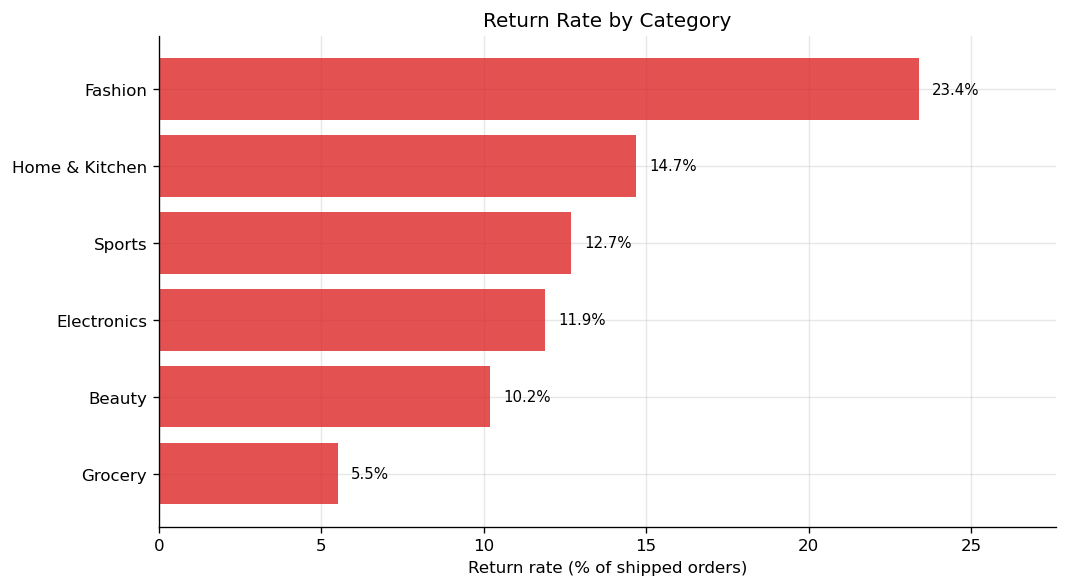

In [5]:
ret_by_cat = (shipped.assign(ret=shipped["order_status"] == "Returned")
              .groupby("category")["ret"].mean().mul(100).round(1)
              .sort_values(ascending=False))
print(ret_by_cat.to_string())

s = ret_by_cat.sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(s.index, s.values, color=RED, alpha=0.8)
ax.set_xlabel("Return rate (% of shipped orders)")
ax.set_title("Return Rate by Category")
for i, v in enumerate(s.values):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, s.values.max() * 1.18)
plt.tight_layout(); plt.show()

Why customers return things (% of all returns):
return_reason
Size issue                 27.1
Quality not as expected    20.6
Damaged                    14.0
Changed mind               12.3
Wrong item                 10.5
Late delivery               9.4
Not recorded                6.1


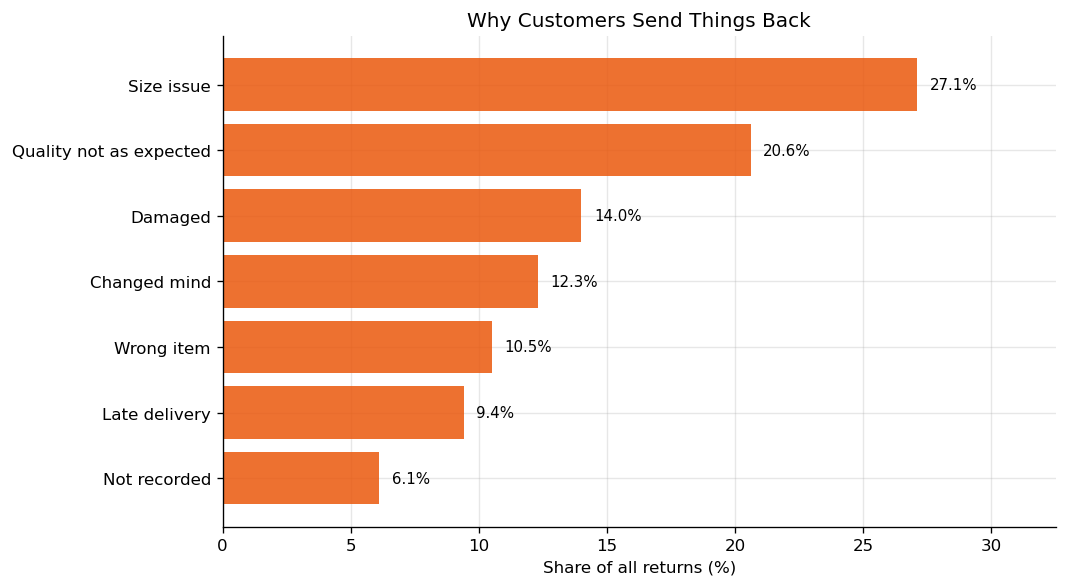

In [6]:
reason_share = (returned["return_reason"].value_counts()
                / len(returned) * 100).round(1)
print("Why customers return things (% of all returns):")
print(reason_share.to_string())

s = reason_share.sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(s.index, s.values, color=ORANGE, alpha=0.85)
ax.set_xlabel("Share of all returns (%)")
ax.set_title("Why Customers Send Things Back")
for i, v in enumerate(s.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, s.values.max() * 1.2)
plt.tight_layout(); plt.show()

**What I see:** Fashion is returned the most — **23.4%**
of shipped fashion orders come back. And the top return reason overall is
**"Size issue" (27.1% of all returns)**.
That is not a product quality problem — that is a size-chart problem. It can
be fixed on the product page itself.

## 6 · COD vs prepaid — is the owner's doubt right?

Cash on delivery is very common in India. The question is what it costs.

payment_mode
COD           18.3
NetBanking    13.7
Card          12.7
UPI           12.4


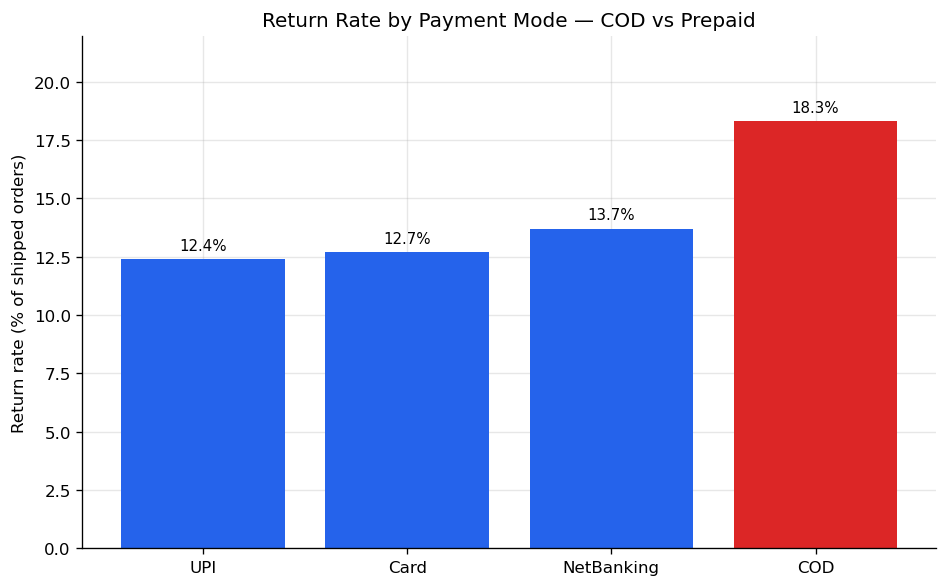

In [7]:
ret_by_pay = (shipped.assign(ret=shipped["order_status"] == "Returned")
              .groupby("payment_mode")["ret"].mean().mul(100).round(1)
              .sort_values(ascending=False))
print(ret_by_pay.to_string())

s = ret_by_pay.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(s.index, s.values, color=[RED if i == "COD" else BLUE for i in s.index])
ax.set_ylabel("Return rate (% of shipped orders)")
ax.set_title("Return Rate by Payment Mode — COD vs Prepaid")
for i, v in enumerate(s.values):
    ax.text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylim(0, s.values.max() * 1.2)
plt.tight_layout(); plt.show()

**What I see:** yes, the owner is right. COD orders come back
**18.3%** of the time, against **12.7%**
for prepaid orders. On top of that, every delivered COD order also pays a
₹45 handling fee. The weakest mix in the whole business is
**Fashion + COD**: 1,174 orders earned only
about **₹40 per order** on average.

## 7 · Discounts — more orders, but more money?

During the festival months the seller gives deeper discounts and gets many
more orders. I grouped all orders by discount size to see what each group
really earns.

In [8]:
df["discount_band"] = pd.cut(df["discount_pct"], bins=[-0.1, 10, 25, 40, 60],
                             labels=["0-10%", "10-25%", "25-40%", "40%+"])
band = df.groupby("discount_band", observed=True).agg(
    orders=("order_id", "count"),
    avg_profit=("profit", "mean"),
    total_profit=("profit", "sum")).round(1)
print(band.to_string())

monthly = df.groupby("month").agg(orders=("order_id", "count"))
monthly["revenue"] = [delivered[delivered["month"] == m]["order_value"].sum()
                       for m in monthly.index]
monthly["profit"] = [df[df["month"] == m]["profit"].sum() for m in monthly.index]
print("\nBusiest months vs a normal month:")
print(monthly.loc[["2025-05", "2025-10", "2025-11"]].round(0).to_string())

               orders  avg_profit  total_profit
discount_band                                  
0-10%            1930       465.5      898482.8
10-25%           4934       277.7     1370101.2
25-40%           2804        58.1      163002.4
40%+              252      -105.8      -26658.5

Busiest months vs a normal month:
         orders    revenue    profit
month                               
2025-05     808   993221.0  225369.0
2025-10    1269  1335794.0  194449.0
2025-11    1179  1316301.0  203709.0


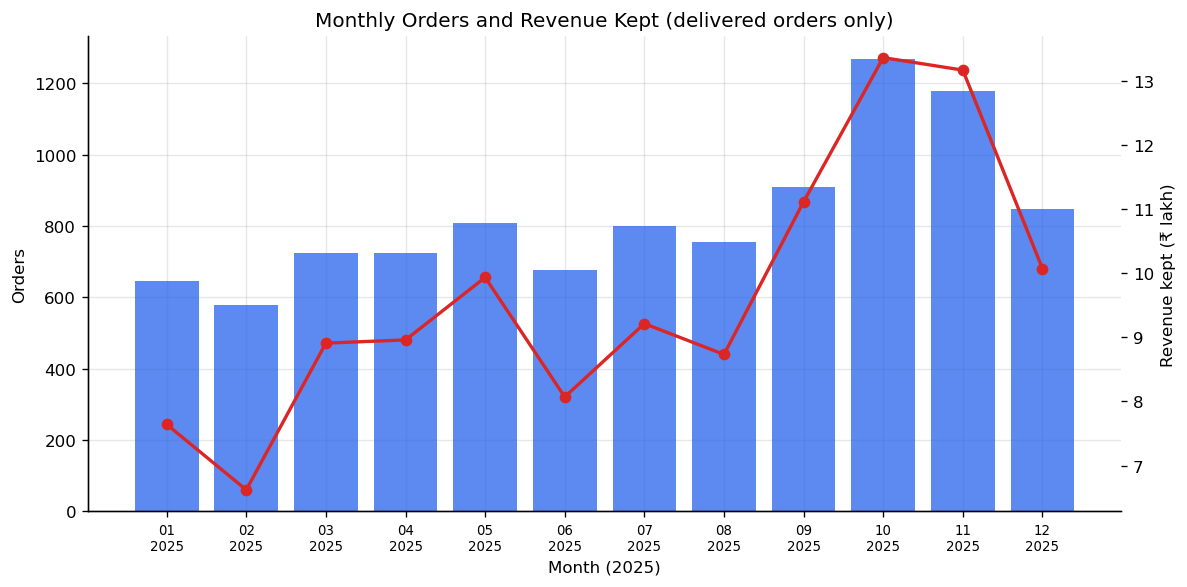

In [9]:
x = range(len(monthly))
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(x, monthly["orders"], color=BLUE, alpha=0.75)
ax1.set_ylabel("Orders")
ax1.set_xticks(x)
ax1.set_xticklabels([m[5:] + "\n" + m[:4] for m in monthly.index], fontsize=8)
ax1.set_xlabel("Month (2025)")
ax2 = ax1.twinx()
ax2.plot(x, monthly["revenue"] / 1e5, color=RED, marker="o", linewidth=2)
ax2.set_ylabel("Revenue kept (₹ lakh)")
ax2.grid(False)
ax1.set_title("Monthly Orders and Revenue Kept (delivered orders only)")
plt.tight_layout(); plt.show()

**What surprised me:** October had the most orders of the year
(1,269) and the most revenue (₹13.4 lakh), but its profit
(₹1.9 lakh) was *lower* than May (₹2.3 lakh from only
808 orders). The festival discount gave the margin away.
And it gets worse at the top end: orders with a **40%+ discount lose about
₹106 per order** on average. Deep discounts do not
just earn less — past a point, they earn nothing at all.

## 8 · Slow delivery and far-off cities

Last doubt to check: does a slow delivery make a return more likely?

delivery_bucket
1-2 days    14.5
3-4 days    14.2
5-6 days    16.2
7+ days     17.7


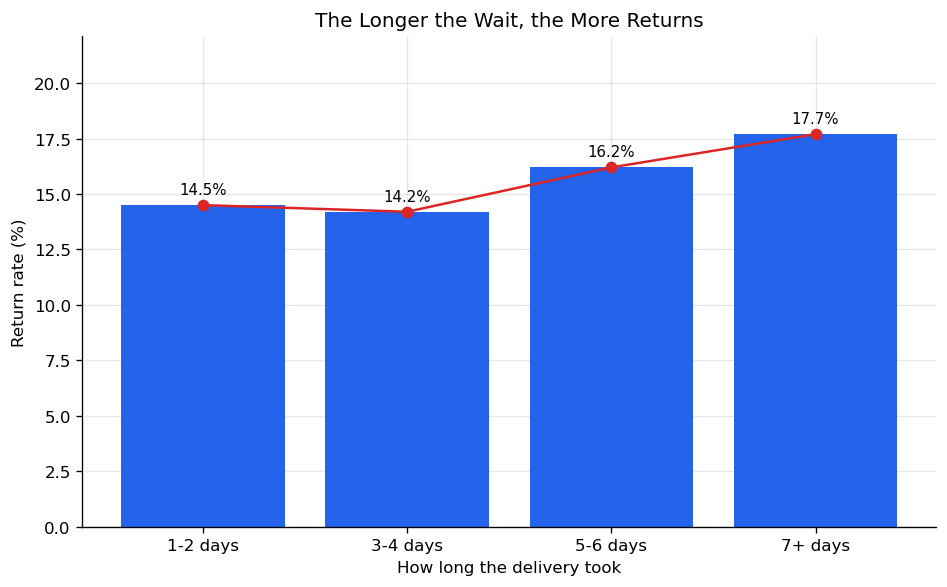


Return rate by city (worst 5):
city
Patna        17.7
Jaipur       17.6
Kochi        17.3
Hyderabad    16.0
Chennai      15.6


In [10]:
shipped["delivery_bucket"] = pd.cut(
    shipped["delivery_days"], bins=[0, 2, 4, 6, 30],
    labels=["1-2 days", "3-4 days", "5-6 days", "7+ days"])
deliv = (shipped.assign(ret=shipped["order_status"] == "Returned")
         .groupby("delivery_bucket", observed=True)["ret"]
         .mean().mul(100).round(1))
print(deliv.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(deliv.index.astype(str), deliv.values, color=BLUE)
ax.plot(deliv.index.astype(str), deliv.values, color=RED, marker="o")
ax.set_ylabel("Return rate (%)")
ax.set_xlabel("How long the delivery took")
ax.set_title("The Longer the Wait, the More Returns")
for i, v in enumerate(deliv.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylim(0, deliv.values.max() * 1.25)
plt.tight_layout(); plt.show()

ret_by_city = (shipped.assign(ret=shipped["order_status"] == "Returned")
               .groupby("city")["ret"].mean().mul(100).round(1)
               .sort_values(ascending=False))
print("\nReturn rate by city (worst 5):")
print(ret_by_city.head(5).to_string())

**What I see:** the pattern is steady — orders that take **7+ days**
come back 17.7% of the time, against
14.5% for 1–2 day delivery. The worst city is
**Patna**: a 17.7% return rate with an average
delivery time of 5.8 days. Slow cities and high returns
go together.

## 9 · Checking the same answers with SQL

I also loaded the cleaned data into SQLite and asked some of the same
business questions in SQL — partly to double-check my pandas numbers, and
partly because this is how the work looks in a real job.

In [11]:
conn = sqlite3.connect(":memory:")
df.to_sql("orders", conn, index=False)

def q(sql):
    return pd.read_sql(sql, conn)

print("Loaded rows into SQLite:", q("SELECT COUNT(*) AS n FROM orders")["n"][0])

Loaded rows into SQLite: 9920


In [12]:
# Q1. Which cities bring in the most revenue (delivered orders)?
q("""SELECT city, COUNT(*) AS delivered_orders,
       ROUND(SUM(order_value)) AS revenue
FROM orders
WHERE order_status = 'Delivered'
GROUP BY city
ORDER BY revenue DESC
LIMIT 5""")

,city,delivered_orders,revenue
0,Delhi,1000,1446095.0
1,Bengaluru,908,1336960.0
2,Mumbai,880,1306745.0
3,Hyderabad,608,928426.0
4,Chennai,588,829085.0


In [13]:
# Q2. Return rate by category
q("""SELECT category,
       COUNT(*) AS shipped_orders,
       SUM(CASE WHEN order_status = 'Returned' THEN 1 ELSE 0 END) AS returns,
       ROUND(100.0 * SUM(CASE WHEN order_status = 'Returned' THEN 1 ELSE 0 END)
             / COUNT(*), 1) AS return_rate_pct
FROM orders
WHERE order_status IN ('Delivered', 'Returned')
GROUP BY category
ORDER BY return_rate_pct DESC""")

,category,shipped_orders,returns,return_rate_pct
0,Fashion,2674,626,23.4
1,Home & Kitchen,1698,249,14.7
2,Sports,750,95,12.7
3,Electronics,2224,265,11.9
4,Beauty,1055,108,10.2
5,Grocery,927,51,5.5


In [14]:
# Q3. Monthly revenue and profit
q("""SELECT month,
       COUNT(*) AS orders,
       ROUND(SUM(CASE WHEN order_status = 'Delivered'
                      THEN order_value ELSE 0 END)) AS revenue_kept,
       ROUND(SUM(profit)) AS profit
FROM orders
GROUP BY month
ORDER BY month""")

,month,orders,revenue_kept,profit
0,2025-01,646,764109.0,177302.0
1,2025-02,580,662073.0,149418.0
2,2025-03,724,890765.0,205641.0
3,2025-04,724,895757.0,201108.0
4,2025-05,808,993221.0,225369.0
5,2025-06,676,806940.0,181537.0
6,2025-07,800,921167.0,205542.0
7,2025-08,756,873140.0,189924.0
8,2025-09,909,1111008.0,249590.0
9,2025-10,1269,1335794.0,194449.0


In [15]:
# Q4. Best and worst products by profit (only products with 100+ orders)
q("""SELECT product, category, COUNT(*) AS orders,
       ROUND(SUM(profit)) AS total_profit
FROM orders
GROUP BY product, category
HAVING COUNT(*) >= 100
ORDER BY total_profit DESC
LIMIT 5""")
print("... and the other end:")
q("""SELECT product, category, COUNT(*) AS orders,
       ROUND(SUM(profit)) AS total_profit
FROM orders
GROUP BY product, category
HAVING COUNT(*) >= 100
ORDER BY total_profit ASC
LIMIT 5""")

... and the other end:


,product,category,orders,total_profit
0,Gym Gloves,Sports,155,11057.0
1,Men's Cotton T-Shirt,Fashion,495,16222.0
2,Yoga Mat 6mm,Sports,168,16990.0
3,Sunscreen SPF 50,Beauty,203,17355.0
4,Herbal Shampoo,Beauty,211,18244.0


In [16]:
# Q5. COD vs prepaid: orders, return rate and average profit per order
q("""SELECT CASE WHEN payment_mode = 'COD' THEN 'COD' ELSE 'Prepaid' END AS pay_type,
       COUNT(*) AS orders,
       ROUND(100.0 * SUM(CASE WHEN order_status = 'Returned' THEN 1 ELSE 0 END)
             / SUM(CASE WHEN order_status IN ('Delivered', 'Returned')
                      THEN 1 ELSE 0 END), 1) AS return_rate_pct,
       ROUND(AVG(profit), 1) AS avg_profit_per_order
FROM orders
GROUP BY pay_type""")

,pay_type,orders,return_rate_pct,avg_profit_per_order
0,COD,4149,18.3,194.7
1,Prepaid,5771,12.7,276.8


## 10 · Profit by category — the full picture

One last chart before I sum up: what each category actually earned after
product cost, return shipping and COD fees.

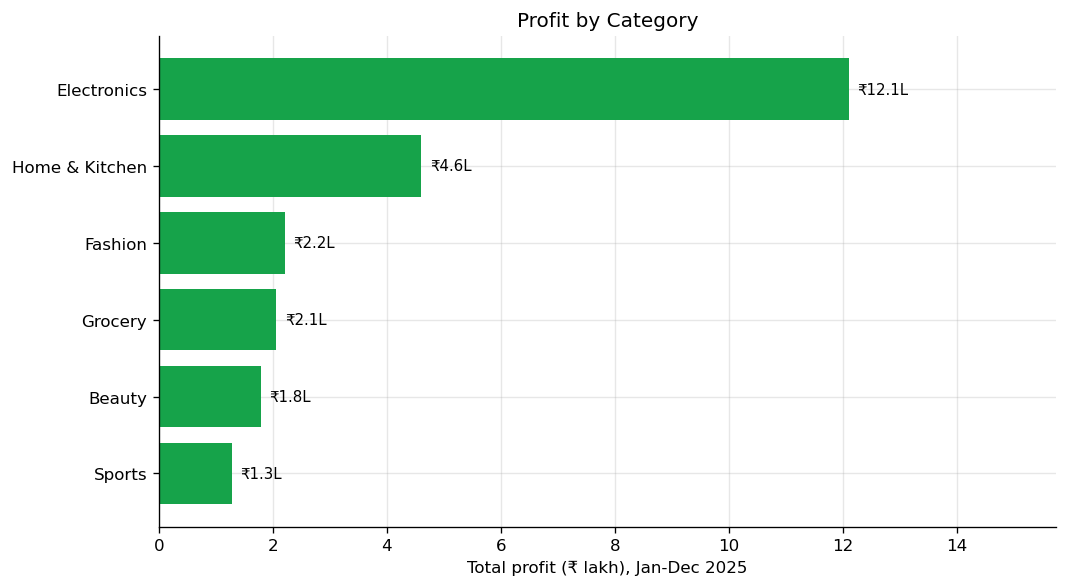

category
Sports             127552.0
Beauty             178438.0
Grocery            206424.0
Fashion            221157.0
Home & Kitchen     460753.0
Electronics       1210604.0


In [17]:
profit_by_cat = df.groupby("category")["profit"].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
colors = [GREEN if v >= 0 else RED for v in profit_by_cat.values]
ax.barh(profit_by_cat.index, profit_by_cat.values / 1e5, color=colors)
ax.set_xlabel("Total profit (₹ lakh), Jan-Dec 2025")
ax.set_title("Profit by Category")
for i, v in enumerate(profit_by_cat.values):
    ax.text(v / 1e5 + 0.15, i, f"₹{v / 1e5:.1f}L", va="center", fontsize=9)
ax.set_xlim(0, (profit_by_cat.values / 1e5).max() * 1.3)
plt.tight_layout(); plt.show()
print(profit_by_cat.round(0).to_string())

## 11 · What I found

1. **Returns are the biggest leak.** 14.9% of shipped orders came
   back — 1,394 returns in the year, and just the return shipping cost
   ₹2.5 lakh, before counting the lost sales.
2. **Fashion is the problem child.** It has the highest return rate
   (23.4%) and "Size issue" is the top return reason
   (27.1% of all returns). Fashion sells a lot but keeps
   very little: its margin is only 8.9% against
   26.3% for Electronics.
3. **COD costs more than it looks.** COD return rate: 18.3%. Prepaid:
   12.7%. Add the ₹45 handling fee on every delivered COD order
   and the gap grows. Fashion + COD is the weakest mix of all — about
   ₹40 profit per order.
4. **Deep discounts lose money.** Orders at 0–10% discount earn about
   ₹466 per order on average. At 25–40% that falls to about
   ₹58, and at 40%+ the seller *loses* about
   ₹106 per order. October proved it: most orders,
   most revenue, less profit than May.
5. **Slow delivery means more returns.** 1–2 day delivery:
   14.5% returns. 7+ days:
   17.7%. Patna is the worst city
   (17.7% returns, 5.8 days average delivery);
   Delhi is the best (13.3%).
6. **Electronics quietly pays the bills.** It is not the biggest seller by
   orders, but it earns the most profit — ₹12.1 lakh of the
   ₹24.0 lakh total.

## 12 · What the business should do

1. **Fix the fashion size charts first.** Add a clear size chart, a "check
   your size" note, and real fit photos on fashion pages. Even a small drop
   in size returns is worth a lot — fashion sees the most orders.
2. **Push prepaid gently.** Free shipping or a small extra discount on
   prepaid orders. Every order that moves from COD to prepaid is less
   likely to come back and saves the ₹45 fee.
3. **Put a floor under discounts.** Keep most discounts at or below 25%.
   A 40%+ discount lost money on almost every order in this data.
4. **Speed up the slow cities.** A closer warehouse or a faster courier
   for Patna and the other slow cities. Faster delivery is not
   just good service — it directly cuts returns.
5. **Be careful with Fashion + COD.** Asking for a small advance payment
   on COD fashion orders would filter out the least serious orders.
6. **Plan festival sales with profit in mind, not just orders.** October
   showed that the biggest month is not always the best month.

## What I learned

- Real data is messy first and useful later. Half the work was cleaning:
  dates, city names, missing values, duplicates.
- A return is not just a lost sale — it is a lost sale *plus* a shipping
  bill. Profit numbers change completely once you count it.
- The most interesting answer was the one I did not expect: the busiest
  month was not the most profitable month. Always check profit, not just
  sales.
- SQL and pandas gave the same answers, which is a good check on both.

*Next step for this project: build the same findings into a Power BI
dashboard, and add a simple check that flags orders likely to be returned
before they are shipped.*